# Unidad 4 · Actividad 1 — Optimización controlada del modelo de transfer learning
## Técnicas Avanzadas de Modelado en IA — Maestría en Inteligencia Artificial

Integrantes:
    - Luis Jorge García
    - Luis Eduardo Uribe
    - Felipe Barreto Patiño


Contexto:

El mejor modelo de la entrega anterior en el notebook
(notebooks/unidad_3/actividad_3_unidad_3_transfer_learning.ipynb) es un transfer learning utilizando ResNet18 preentrenado en
ImageNet con fine-tuning completo que clasifica el los 5 keypoints de los jugadores de padel (hombro, codo, muñeca, raqueta,
cabeza) de un parche centrado en cada punto anotado: 96,3% de exactitud en test frente a 85,7% de la CNN
propia de la Unidad 2.

**Objetivo:**

Optimizar ese modelo con los **mismos datos y las mismas particiones**,
mediante experimentos controlados sobre hiperparámetros críticos, para esta entrega utlizaremos una instancia de MLflow local donde trackearemos parámetros, métricas por época, métricas de rendimiento de la máquina y artefactos, y validar
cuantitativamente si la versión optimizada mejora a la línea base teniendo en cuenta también sus costos


Configuración, hardware y MLflow

In [1]:
import logging, time, warnings
from dataclasses import replace
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display
from collections import Counter

from PIL import Image
from torchvision.transforms import v2 as T
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import confusion_matrix

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
logging.getLogger("mlflow").setLevel(logging.ERROR)

ROOT = Path.cwd().resolve()
while not (ROOT / "data.yaml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "notebooks" / "unidad_4"))
import kpt_optim as K

device = torch.device("cuda")
torch.backends.cudnn.benchmark = True  # velocidad; la variabilidad resultante se mide con 3 semillas (Cp. 8)
K.seed_everything(42)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e87ba4"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

mlflow = K.setup_mlflow(ROOT)
client = mlflow.tracking.MlflowClient()
EXEC_ID = time.strftime("%Y%m%d-%H%M%S")  # identifica esta ejecucion del notebook dentro del experimento
TAGS = {"execution_id": EXEC_ID}

hw = K.hardware_tags()
print("ROOT:", ROOT)
print(f"GPU: {hw.get('gpu')} | CUDA {hw['cuda']} | torch {hw['torch']} | Python {hw['python']}")
print(f"CPU: {hw['cpu']} | commit: {hw.get('git_commit', '-')}")
print(f"MLflow {mlflow.__version__} | tracking URI: {mlflow.get_tracking_uri()}")
print(f"Experimento: unidad4_transfer_optim | execution_id de esta corrida: {EXEC_ID}")

ROOT: C:\Users\luisj\OneDrive\Documentos\Maestria Inteligencia Artificial\Tercer Semestre\Primer Ciclo\Tecnicas_Avanzadas_Modelado_En_IA\Unidad_2\padel-impact-position-detection
GPU: NVIDIA GeForce RTX 4070 Laptop GPU | CUDA 13.2 | torch 2.14.1+cu132 | Python 3.12.10
CPU: Intel64 Family 6 Model 170 Stepping 4, GenuineIntel | commit: 3b080e7
MLflow 3.17.2 | tracking URI: sqlite:///C:/Users/luisj/OneDrive/Documentos/Maestria Inteligencia Artificial/Tercer Semestre/Primer Ciclo/Tecnicas_Avanzadas_Modelado_En_IA/Unidad_2/padel-impact-position-detection/mlflow.db
Experimento: unidad4_transfer_optim | execution_id de esta corrida: 20261024-204029


## Datos: mismas particiones que la línea base

Se reconstruye exactamente la misma data que en entregas anteriores

In [2]:
kpt = K.load_keypoints(ROOT)
counts = pd.crosstab(kpt.split, kpt.label).rename(columns=dict(enumerate(K.KP_NAMES)))
counts = counts.loc[["train", "valid", "test"], K.KP_NAMES]
counts["total"] = counts.sum(axis=1)
counts["rallies"] = kpt.groupby("split").rally_id.nunique()
display(counts)

rallies = {s: set(kpt[kpt.split == s].rally_id) for s in ["train", "valid", "test"]}
assert not (rallies["train"] & rallies["valid"]) and not (rallies["train"] & rallies["test"]) \
    and not (rallies["valid"] & rallies["test"])
print("OK: ningún rally compartido entre particiones. Mismos 3333 / 1136 / 1045 parches que la Unidad 3.")

label,hombro,codo,muneca,raqueta,cabeza,total,rallies
split,,,,,,,
train,679,667,648,657,682,3333,24
valid,236,233,212,208,247,1136,5
test,217,210,201,197,220,1045,6


OK: ningún rally compartido entre particiones. Mismos 3333 / 1136 / 1045 parches que la Unidad 3.


## Pipeline de datos

### Antecedentes

En la Unidad 3 cada parche de entrenamiento se recortaba de la imagen original usando PIL, se redimensionaba y se aumentaba (flip, rotación, color). Cada época tardaba alrededor de 26 segs y casi no variaba entre entrenar 2565 parámetros (linear probe) u 11 millones (fine-tuning completo): el cuello de botella no era la red sino la carga de datos. Con 15 minutos por corrida, una búsqueda de hiperparámetros dentro del presupuesto de 1 hora de GPU no era la mejor opción para nosotros

### Solucón propuesta

Cada parche se recorta una sola vez desde la imagen original, con un margen de contexto de 1.7 el lado del parche, y se guarda en la GPU. Toda la augmentación de la Unidad 3 se aplica después por lotes en la GPU:

Valid y test usan el recorte central sin augmentación como antes

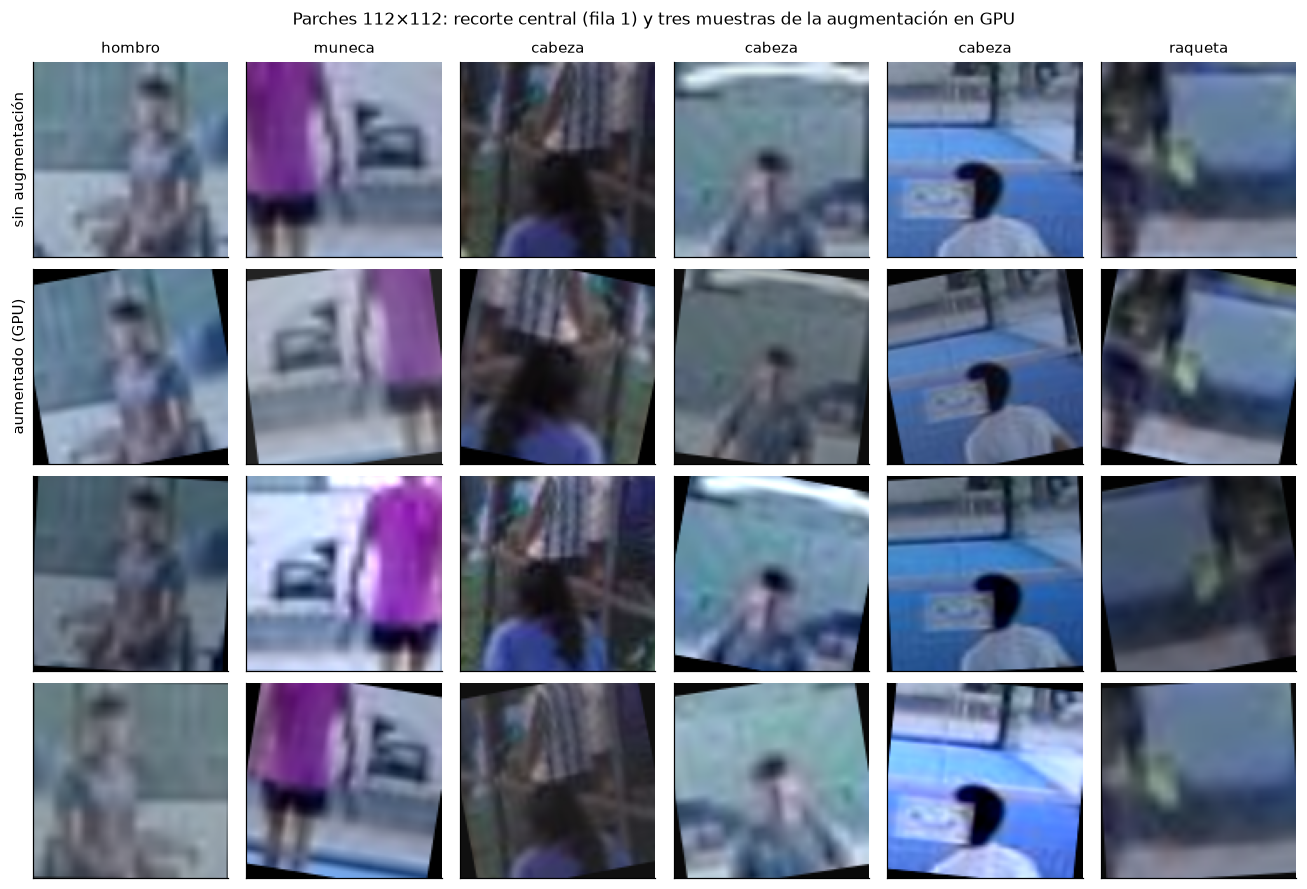

In [3]:
DATA = {112: K.PatchData(kpt, 112, "imagenet", device)}

def get_data(size):
    if size not in DATA:
        DATA[size] = K.PatchData(kpt, size, "imagenet", device)
    return DATA[size]

def to_img(x, patches):
    return (x.float() * patches.std[0] + patches.mean[0]).clamp(0, 1).permute(1, 2, 0).cpu().numpy()

tr = DATA[112]["train"]
gen = torch.Generator(device=device).manual_seed(0)
pick = torch.tensor([10, 400, 900, 1500, 2200, 3100], device=device)
one, zero = torch.ones(len(pick), device=device), torch.zeros(len(pick), device=device)
center = tr._crop(tr.x[pick].float() / 255, one, zero, zero, one)  # escala 1, sin desplazamiento ni flip
fig, axes = plt.subplots(4, 6, figsize=(12, 8.2))
for j in range(6):
    axes[0, j].imshow(center[j].permute(1, 2, 0).cpu().numpy())
    axes[0, j].set_title(K.KP_NAMES[int(tr.y[pick[j]])], fontsize=10)
for r in range(1, 4):
    xa, _ = tr.augmented(pick, K.AUG_LEVELS["original"], gen)
    for j in range(6):
        axes[r, j].imshow(to_img(xa[j], tr))
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("sin augmentación"); axes[1, 0].set_ylabel("aumentado (GPU)")
plt.suptitle("Parches 112×112: recorte central (fila 1) y tres muestras de la augmentación en GPU", fontsize=11)
plt.tight_layout(); plt.show()

Preparar una época de datos de train — CPU (Unidad 3): 7.55 s | GPU (Unidad 4): 0.170 s → 44× más rápido


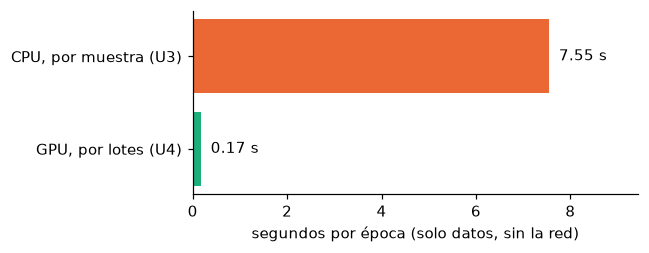

In [4]:
frame = DATA[112].frames["train"]
IMAGES = {p: Image.open(p).convert("RGB") for p in frame.image_path.unique()}
AUG_U3 = T.Compose([T.RandomHorizontalFlip(0.5), T.RandomRotation(12),
                    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02)])
to_tensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])
normalize = T.Normalize(K.IMAGENET_MEAN, K.IMAGENET_STD)
rng = np.random.default_rng(42)

def crop_u3(row, out=112):  # identico a crop_patch() de la Unidad 3
    im = IMAGES[row.image_path]
    W, H = im.size
    side = float(np.clip(row.bbox_h * H * K.PATCH_FRAC, K.MIN_PATCH, K.MAX_PATCH)) * rng.uniform(0.85, 1.15)
    px, py = row.x * W + rng.uniform(-0.1, 0.1) * side, row.y * H + rng.uniform(-0.1, 0.1) * side
    return im.crop((px - side / 2, py - side / 2, px + side / 2, py + side / 2)).resize((out, out), Image.BILINEAR)

t0 = time.perf_counter()
for r in frame.itertuples():
    normalize(AUG_U3(to_tensor(crop_u3(r))))
t_cpu = time.perf_counter() - t0

def gpu_epoch():
    g = torch.Generator(device=device).manual_seed(1)
    for i in range(0, len(tr), 64):
        tr.augmented(torch.arange(i, min(i + 64, len(tr)), device=device), K.AUG_LEVELS["original"], g)
    torch.cuda.synchronize()

gpu_epoch()  # calentamiento
t0 = time.perf_counter(); gpu_epoch(); t_gpu = time.perf_counter() - t0

print(f"Preparar una época de datos de train — CPU (Unidad 3): {t_cpu:.2f} s | GPU (Unidad 4): {t_gpu:.3f} s "
      f"→ {t_cpu / t_gpu:.0f}× más rápido")
fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(["GPU, por lotes (U4)", "CPU, por muestra (U3)"], [t_gpu, t_cpu], color=[PALETTE[2], PALETTE[1]])
for i, v in enumerate([t_gpu, t_cpu]):
    ax.text(v, i, f"  {v:.2f} s", va="center")
ax.set_xlabel("segundos por época (solo datos, sin la red)"); ax.set_xlim(0, t_cpu * 1.25)
plt.tight_layout()
with mlflow.start_run(run_name="C1_datos_pipeline", tags={**TAGS, "sweep": "setup"}):
    mlflow.log_metrics({"pipeline_cpu_epoch_s": t_cpu, "pipeline_gpu_epoch_s": t_gpu, "pipeline_speedup": t_cpu / t_gpu,
                        **{f"n_{s}": int(counts.loc[s, "total"]) for s in counts.index},
                        **{f"rallies_{s}": int(counts.loc[s, "rallies"]) for s in counts.index}})
    mlflow.log_text(counts.to_csv(), "particiones.csv")
    mlflow.log_figure(fig, "pipeline_cpu_vs_gpu.png")
plt.show()

## Arquitectura de la red avanzada

Para esta entrega vamos a utilizar el mismo backbone **ResNet18** preentrenada y adaptada a 5 clases:

A continuación la arquitectura propuesta (se lo pedimos a la IA):

| Bloque | Capas | Función |
|---|---|---|
| `stem` | Conv 7×7/2 (64) → BN → ReLU → MaxPool 3×3/2 | reduce la resolución ×4 y extrae bordes y texturas de bajo nivel |
| `layer1`–`layer4` | 2 *BasicBlocks* residuales por etapa (64 → 128 → 256 → 512 canales); `layer2`–`layer4` reducen ×2 | las **conexiones residuales** (`x + F(x)`) mantienen el gradiente estable en una red de 18 capas; cada etapa compone patrones más abstractos (piel, ropa, silueta de la raqueta) |
| `pool` | Global Average Pooling | resume el mapa final en un vector de 512, invariante a la posición exacta |
| `head` | Dropout(0,3) → Linear(512, 5) | clasificador; el dropout regulariza la única capa entrenada desde cero |


### Por qué transfer learning?

Con solo 3333 parches de entrenamiento, los filtros aprendidos en ImageNet aportan detectores de bordes, texturas y formas que la CNN propia no puede aprender con tan pocos datos. Durante el fine tuning completo, la normalización por lotes se reentrena con las estadísticas del dominio de pádel.

La pérdida es entropía cruzada.

In [5]:
m = K.TransferNet().to(device).eval().set_trainable(K.STAGES)
rows = []
for size in [112, 160]:
    x = torch.zeros(1, 3, size, size, device=device)
    for name in K.STAGES:
        x = m.blocks[name](x)
        rows.append(dict(entrada=f"{size}×{size}", bloque=name, salida=f"{x.shape[1]}×{x.shape[2]}×{x.shape[3]}"))
shapes = pd.DataFrame(rows).pivot(index="bloque", columns="entrada", values="salida").loc[K.STAGES]
params = pd.DataFrame([dict(bloque=n, parametros=sum(p.numel() for p in m.blocks[n].parameters())) for n in K.STAGES]
                      + [dict(bloque="head", parametros=sum(p.numel() for p in m.head.parameters()))]).set_index("bloque")
display(params.join(shapes).fillna("—"))
tot, trn = K.count_params(m)
cnn_tot, _ = K.count_params(K.KptTypeCNN())
print(f"TransferNet: {tot:,} parámetros ({trn:,} entrenables en fine-tuning completo) | "
      f"CNN de la Unidad 2: {cnn_tot:,} parámetros → {tot / cnn_tot:.0f}× más capacidad")
del m

,parametros,112×112,160×160
bloque,,,
stem,9536,64×28×28,64×40×40
layer1,147968,64×28×28,64×40×40
layer2,525568,128×14×14,128×20×20
layer3,2099712,256×7×7,256×10×10
layer4,8393728,512×4×4,512×5×5
head,2565,—,—


TransferNet: 11,179,077 parámetros (11,179,077 entrenables en fine-tuning completo) | CNN de la Unidad 2: 24,133 parámetros → 463× más capacidad


## Protocolo experimental y registro en MLflow


### Diseño del experimento 

En la entrega anterior el mejor modelo se eligió comparando el F1 en **test**, y valid solo se usó para la parada temprana. Aquí, todas las decisione se toman con el conjunto de validación, y el test ayuda a evaluar **una sola vez**, al final del notebook, sobre los modelos ya elegidos.

  1. **Métrica de selección:** F1 macro en valid (las 5 clases pesan igual), con la pérdida en valid como desempate.
  2. **Protocolo controlado.** Todas las corridas de la búsqueda comparten datos, split, semilla, arquitectura y presupuesto de cómputo: 30 épocas con calentamiento lineal de 2 épocas y coseno completo. El checkpoint guardado es la mejor época en valid.
  3. **Búsqueda coordinada (un factor a la vez).** Cada barrido varía un hiperparámetro manteniendo fija la mejor configuración encontrada hasta ese momento (la incumbente). Una variante solo reemplaza a la incumbente si mejora el F1 en valid en al menos 0,002 diferencias menores están dentro del ruido de una sola semilla y se prefiere la configuración ya validada.

### Para qué sirve MLflow?

por experiencias pasadas, MLFlow nos ha servido como centro de experimentación y control de corridas de modelos, lo hemos utilizado antes durante la maestría y eso nos motivó a implementarlo para el registro de este modelo de CV.

El experimento queda nombrado como **unidad4_transfer_optim**, un run padre por barrido con un run anidado por configuración:

- *parámetros*: la configuración completa, más tags de hardware (GPU, CUDA, torch, CPU) y el execution_id de esta ejecución
- *métricas por época*: pérdida y exactitud de train y valid, F1 en valid, tasa de aprendizaje, tiempo por época y throughput (parches/s)
- *métricas de rendimiento de la máquina*: muestreo automático de MLflow cada 2 segundos (% de uso   de GPU, memoria y potencia de GPU, % de CPU, RAM), más VRAM pico, tiempo total de entrenamiento, parámetros, tamaño del checkpoint y, para los modelos finales, latencia de inferencia (p50/p95) en GPU y CPU.
- *artefactos*: curvas de aprendizaje, historial por época en formato CSV, matriz de confusión de valid, la configuración en JSON y, para los modelos finales, los pesos y el modelo registrado con mlflow.pytorch

Todas las tablas de este notebook se construyen consultando MLflow, no a mano.

In [6]:
MIN_GAIN = 0.002
RESULTS, JOURNEY = {}, []
incumbent = None

def run(cfg, sweep, **kw):
    res = K.run_experiment(cfg, get_data(cfg.img_size), device, sweep, tags=TAGS, **kw)
    res["sweep"] = sweep
    RESULTS[cfg.name] = res
    print(f"  {cfg.name:<38} F1 valid {res['val_f1_best']:.4f} | acc {res['val_acc_best']:.4f} | "
          f"mejor época {res['best_epoch']:>3}/{res['epochs_run']:<3} | gap train−valid {res['train_val_gap_acc']:+.3f} | "
          f"{res['train_time_s']:.0f} s")
    return res

def runs_table(names, factor_cols=()):
    rows = []
    for n in names:
        r = client.get_run(RESULTS[n]["run_id"])
        mt, pr = r.data.metrics, r.data.params
        sysm = K.system_metric_stats(RESULTS[n]["run_id"])
        rows.append({"corrida": n, **{c: pr.get(c) for c in factor_cols},
                     "F1 valid": mt["val_f1_best"], "acc valid": mt["val_acc_best"], "loss valid": mt["val_loss_best"],
                     "gap train−valid": mt["train_val_gap_acc"], "mejor época": int(mt["best_epoch"]),
                     "tiempo (s)": mt["train_time_s"], "s/época": mt["median_epoch_time_s"],
                     "VRAM pico (MB)": mt["vram_peak_mb"], "GPU % medio": sysm["gpu_0_utilization_percentage_mean"]})
    return pd.DataFrame(rows).set_index("corrida")

def plot_curves(names, title):
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
    for i, n in enumerate(names):
        h, c = RESULTS[n]["hist"], PALETTE[i % len(PALETTE)]
        axes[0].plot(h.epoch, h.train_loss, c=c, ls="--", lw=1.2)
        axes[0].plot(h.epoch, h.val_loss, c=c, lw=1.8, label=n)
        axes[1].plot(h.epoch, h.train_acc, c=c, ls="--", lw=1.2)
        axes[1].plot(h.epoch, h.val_acc, c=c, lw=1.8, label=n)
    axes[0].set_title("pérdida (— valid, - - train)"); axes[1].set_title("exactitud (— valid, - - train)")
    for ax in axes:
        ax.set_xlabel("época")
    axes[1].legend(fontsize=8, loc="lower right"); axes[1].set_ylim(0.6, 1.0)
    fig.suptitle(title, fontsize=11); plt.tight_layout()
    return fig

def sweep(name, factor, options, hypothesis, base=None, benchmark=False):
    # Barrido de un factor: options = lista de dicts con los cambios respecto de la incumbente
    global incumbent
    ref = incumbent["cfg"] if incumbent else base
    print(f"{name} — {hypothesis}")
    names = []
    with mlflow.start_run(run_name=name, tags={**TAGS, "sweep": name, "factor": factor}):
        mlflow.log_param("hipotesis", hypothesis)
        for ov in options:
            if incumbent and all(getattr(incumbent["cfg"], k) == v for k, v in ov.items()):
                names.append(incumbent["cfg"].name)
                print(f"  {incumbent['cfg'].name:<38} (incumbente: se reutiliza, misma configuración y semilla)")
                if benchmark and "infer_gpu_bs1_p50_ms" not in incumbent:
                    b = K.inference_benchmark(incumbent["model"], incumbent["cfg"].img_size, device)
                    incumbent.update(b); K.log_to_run(incumbent["run_id"], b)
                # copia de la incumbente dentro de este barrido: asi MLflow compara TODAS sus variantes
                K.clone_as_reference(incumbent["run_id"], f"{name}:incumbente ({incumbent['cfg'].name})", name, tags=TAGS)
                continue
            label = ",".join(f"{k}={v}" for k, v in ov.items())
            names.append(run(replace(ref, name=f"{name}:{label}", **ov), name, benchmark=benchmark)["cfg"].name)
        cands = [RESULTS[n] for n in names]
        best = max(cands, key=lambda r: (r["val_f1_best"], -r["val_loss_best"]))
        before = incumbent["val_f1_best"] if incumbent else None
        if incumbent is None or (best is not incumbent and best["val_f1_best"] >= incumbent["val_f1_best"] + MIN_GAIN):
            incumbent, decision = best, "se adopta"
        else:
            decision = "se mantiene la incumbente"
        step = dict(barrido=name, factor=factor, eleccion=incumbent["cfg"].name, val_f1=incumbent["val_f1_best"],
                    val_f1_antes=before, rango_f1=max(r["val_f1_best"] for r in cands) - min(r["val_f1_best"] for r in cands))
        JOURNEY.append(step)
        # resumen del barrido en el run padre (sin val_f1_best, para que el filtro de variantes no lo incluya)
        mlflow.log_params({"seleccion": incumbent["cfg"].name, "decision": decision})
        mlflow.log_metrics({"incumbente_val_f1": incumbent["val_f1_best"], "mejor_variante_val_f1": best["val_f1_best"],
                            "rango_f1": step["rango_f1"], "n_variantes": len(names),
                            **({} if before is None else {"incumbente_val_f1_antes": before,
                                                          "ganancia_val_f1": incumbent["val_f1_best"] - before})})
        cols = sorted({k for ov in options for k in ov})
        table = runs_table(names, cols)
        mlflow.log_text(table.to_csv(), "resumen_variantes.csv")
        fig = plot_curves(names, f"{name}: curvas de aprendizaje por variante")
        mlflow.log_figure(fig, "curvas_variantes.png")
    for n in names:  # libera la GPU: solo se conserva el modelo incumbente
        if RESULTS[n] is not incumbent:
            RESULTS[n]["model"] = None
    display(table.round(4))
    plt.show()
    delta = "" if before is None else f" (F1 valid {before:.4f} → {incumbent['val_f1_best']:.4f}, {incumbent['val_f1_best'] - before:+.4f})"
    print(f"Decisión {name}: {decision} → {incumbent['cfg'].name}{delta}")
    return names

## Línea base reproducida (receta exacta de la Unidad 3)

La línea base es el modelo ganador de la entrega anterior, reentrenado con "su misma receta" sobre las
mismas particiones (no hay pesos guardados de la Unidad 3, y reentrenar garantiza un protocolo idéntico), por eso intentamos replicar esta corrida para registrarla en MLFlow.

Si el pipeline en GPU es fiel al original, la exactitud en valid debe quedar en torno al 0.943 que reportó la Unidad 3 para el fine tuning completo

  E0:receta_U3                           F1 valid 0.9296 | acc 0.9331 | mejor época  68/78  | gap train−valid -0.001 | 88 s


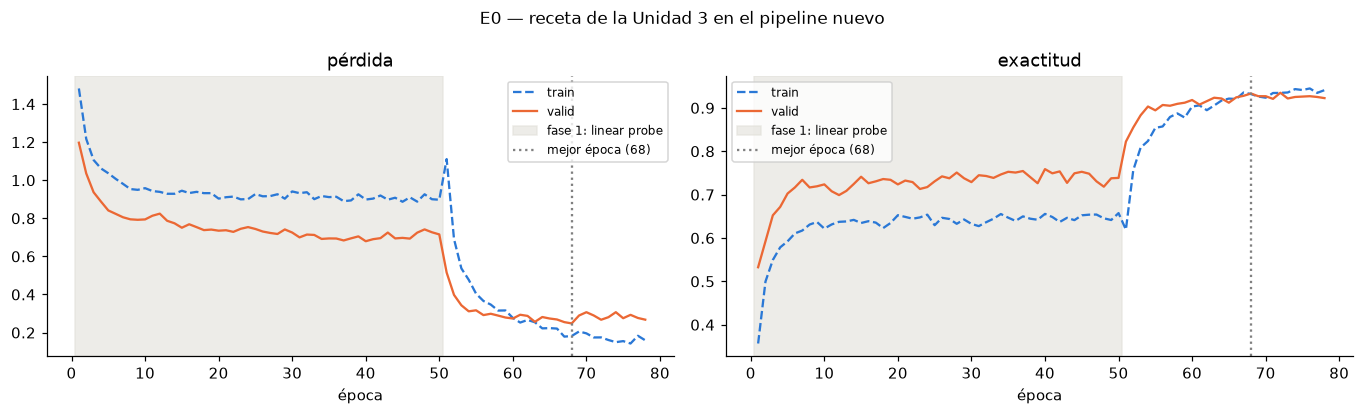

Fase 1 (linear probe): 50 épocas | Fase 2 (FT completo): 28 épocas | tiempo total 88 s (0.65 s/época, vs ~26 s/época en la U3)
Paridad con la Unidad 3 — exactitud valid: 0.9331 aquí vs 0,943 reportado (error estándar de una exactitud ~0,94 con 1136 parches ≈ 0.007)


In [7]:
with mlflow.start_run(run_name="E0_linea_base_U3", tags={**TAGS, "sweep": "E0"}) as e0_parent:
    E0 = run(K.Config(name="E0:receta_U3", recipe="u3_two_phase"), "E0", benchmark=True)

h = E0["hist"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
for ax, (tr_col, va_col, ttl) in zip(axes, [("train_loss", "val_loss", "pérdida"), ("train_acc", "val_acc", "exactitud")]):
    ax.plot(h.epoch, h[tr_col], ls="--", label="train"); ax.plot(h.epoch, h[va_col], label="valid")
    ax.axvspan(0.5, (h.phase == "probe").sum() + 0.5, color="#e1e0d9", alpha=0.6, label="fase 1: linear probe")
    ax.axvline(E0["best_epoch"], c="gray", ls=":", label=f"mejor época ({E0['best_epoch']})")
    ax.set_title(ttl); ax.set_xlabel("época"); ax.legend(fontsize=8)
plt.suptitle("E0 — receta de la Unidad 3 en el pipeline nuevo", fontsize=11); plt.tight_layout()
n_probe = int((h.phase == "probe").sum())
K.log_to_run(E0["run_id"], {"epochs_probe": n_probe, "epochs_finetune": len(h) - n_probe})
K.log_to_run(e0_parent.info.run_id, {"paridad_acc_valid_vs_u3": E0["val_acc_best"] - 0.943})
K.log_artifacts_to_run(E0["run_id"], figures={"curvas_fases.png": fig})
plt.show()

print(f"Fase 1 (linear probe): {n_probe} épocas | Fase 2 (FT completo): {len(h) - n_probe} épocas | "
      f"tiempo total {E0['train_time_s']:.0f} s ({E0['median_epoch_time_s']:.2f} s/época, vs ~26 s/época en la U3)")
print(f"Paridad con la Unidad 3 — exactitud valid: {E0['val_acc_best']:.4f} aquí vs 0,943 reportado "
      f"(error estándar de una exactitud ~0,94 con 1136 parches ≈ {np.sqrt(0.94 * 0.06 / 1136):.3f})")

## Búsqueda controlada de hiperparámetros

### Tasa de aprendizaje y protocolo de entrenamiento

**Hipótesis.** Un LR range test sobre el modelo completo permite ubicar el rango útil. Una tasa "discriminativa" (cabeza 10× más alta que el backbone), con warmup y coseno completo, debería converger mejor ya que el backbone preentrenado necesita ajustes pequeños y la cabeza, que parte de cero, ajustes grandes.

El barrido prueba tres LR de backbone alrededor del valor de la Unidad 3: {3e-5, 1e-4, 3e-4}, con la cabeza a 10×.

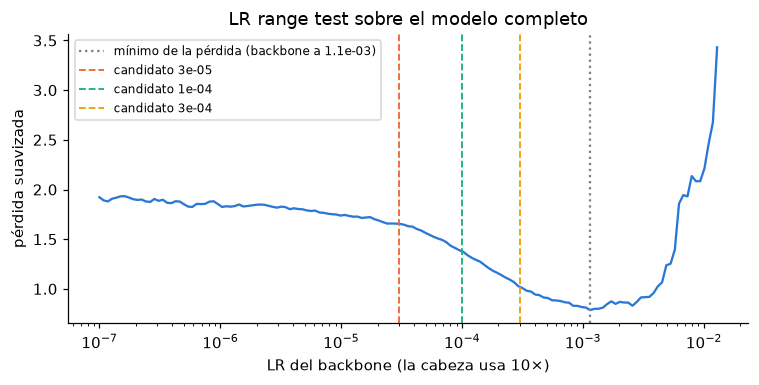

Mínimo de la pérdida en LR backbone = 1.15e-03: los candidatos quedan 1–2 órdenes de magnitud por debajo, en la zona de descenso estable (la regla práctica es mínimo/10).


In [8]:
BASE = K.Config(name="base_U4")  # AdamW, wd 1e-4, dropout 0.3, 112 px, augmentacion original, 30 ep, warmup 2
lrs, losses = K.lr_range_test(BASE, DATA[112], device)
lr_min = lrs[np.argmin(losses)]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogx(lrs, losses, c=PALETTE[0])
ax.axvline(lr_min, c="gray", ls=":", label=f"mínimo de la pérdida (backbone a {lr_min:.1e})")
for v, c in zip([3e-5, 1e-4, 3e-4], PALETTE[1:4]):
    ax.axvline(v, c=c, ls="--", lw=1.2, label=f"candidato {v:.0e}")
ax.set_xlabel("LR del backbone (la cabeza usa 10×)"); ax.set_ylabel("pérdida suavizada")
ax.set_title("LR range test sobre el modelo completo"); ax.legend(fontsize=8); plt.tight_layout()
with mlflow.start_run(run_name="C2_lr_range_test", tags={**TAGS, "sweep": "setup"}):
    mlflow.log_params(BASE.short())
    mlflow.log_metrics({"lr_min_loss": float(lr_min), "lrt_steps": len(lrs)})
    for i, (lr_i, loss_i) in enumerate(zip(lrs, losses)):
        mlflow.log_metrics({"lrt_lr": float(lr_i), "lrt_loss": float(loss_i)}, step=i)
    mlflow.log_figure(fig, "lr_range_test.png")
plt.show()
print(f"Mínimo de la pérdida en LR backbone = {lr_min:.2e}: los candidatos quedan 1–2 órdenes de magnitud "
      f"por debajo, en la zona de descenso estable (la regla práctica es mínimo/10).")

E1_lr — LR discriminativo (cabeza 10×), warmup y coseno completo
  E1_lr:lr_backbone=3e-05,lr_head=0.0003 F1 valid 0.9138 | acc 0.9181 | mejor época  22/30  | gap train−valid -0.018 | 57 s
  E1_lr:lr_backbone=0.0001,lr_head=0.001 F1 valid 0.9378 | acc 0.9410 | mejor época  27/30  | gap train−valid +0.008 | 63 s
  E1_lr:lr_backbone=0.0003,lr_head=0.003 F1 valid 0.9419 | acc 0.9445 | mejor época  29/30  | gap train−valid +0.019 | 63 s


,lr_backbone,lr_head,F1 valid,acc valid,loss valid,gap train−valid,mejor época,tiempo (s),s/época,VRAM pico (MB),GPU % medio
corrida,,,,,,,,,,,
"E1_lr:lr_backbone=3e-05,lr_head=0.0003",3e-05,0.0003,0.9138,0.9181,0.2467,-0.0180,22,56.7425,1.6776,1629.6566,71.0370
"E1_lr:lr_backbone=0.0001,lr_head=0.001",0.0001,0.001,0.9378,0.9410,0.2104,0.0083,27,63.3734,1.7239,1719.3682,76.5667
"E1_lr:lr_backbone=0.0003,lr_head=0.003",0.0003,0.003,0.9419,0.9445,0.1979,0.0192,29,62.5382,1.7834,1810.5871,80.6333


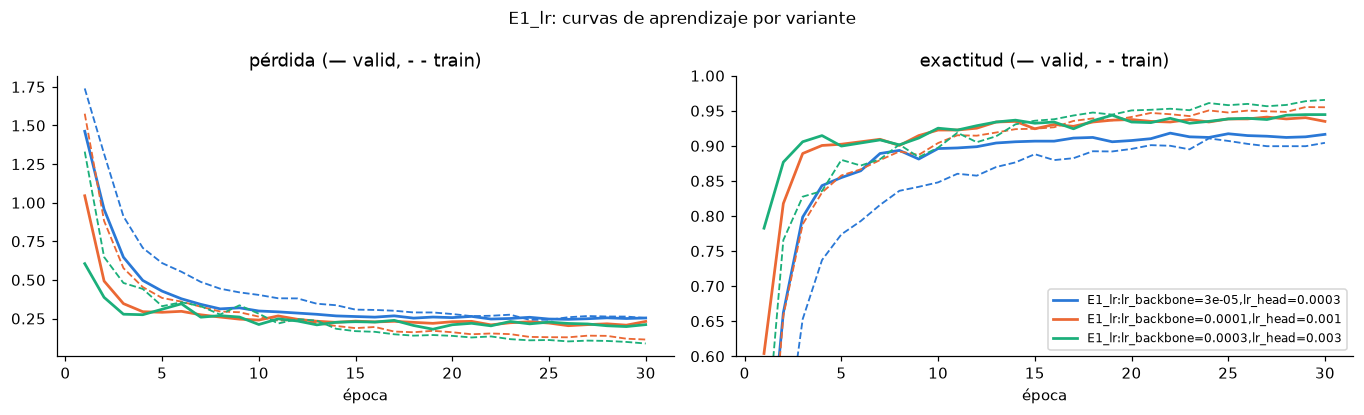

Decisión E1_lr: se adopta → E1_lr:lr_backbone=0.0003,lr_head=0.003
Referencia E0 (receta U3): F1 valid 0.9296


In [9]:
sweep("E1_lr", "lr_backbone",
      [dict(lr_backbone=3e-5, lr_head=3e-4), dict(lr_backbone=1e-4, lr_head=1e-3), dict(lr_backbone=3e-4, lr_head=3e-3)],
      "LR discriminativo (cabeza 10×), warmup y coseno completo", base=BASE)
print(f"Referencia E0 (receta U3): F1 valid {E0['val_f1_best']:.4f}")

### 2) Weight decay

**Hipótesis.** El weight decay quedó fijo en 1e-4. Con AdamW el decaimiento está desacoplado del
gradiente, así que valores más altos (1e-2, 5e-2) son habituales en fine-tuning. Pueden regularizar
mejor, aunque el modelo no muestra sobreajuste, de modo que la ganancia esperada es modesta y podría ser
nula.

E2_weight_decay — regularización L2 desacoplada
  E1_lr:lr_backbone=0.0003,lr_head=0.003 (incumbente: se reutiliza, misma configuración y semilla)
  E2_weight_decay:weight_decay=0.01      F1 valid 0.9467 | acc 0.9489 | mejor época  29/30  | gap train−valid +0.014 | 52 s
  E2_weight_decay:weight_decay=0.05      F1 valid 0.9377 | acc 0.9401 | mejor época  15/30  | gap train−valid -0.032 | 53 s


,weight_decay,F1 valid,acc valid,loss valid,gap train−valid,mejor época,tiempo (s),s/época,VRAM pico (MB),GPU % medio
corrida,,,,,,,,,,
"E1_lr:lr_backbone=0.0003,lr_head=0.003",0.0001,0.9419,0.9445,0.1979,0.0192,29,62.5382,1.7834,1810.5871,80.6333
E2_weight_decay:weight_decay=0.01,0.01,0.9467,0.9489,0.1859,0.0142,29,52.2911,1.5771,1720.8755,82.0400
E2_weight_decay:weight_decay=0.05,0.05,0.9377,0.9401,0.2002,-0.0320,15,52.5649,1.6055,1812.2993,76.8800


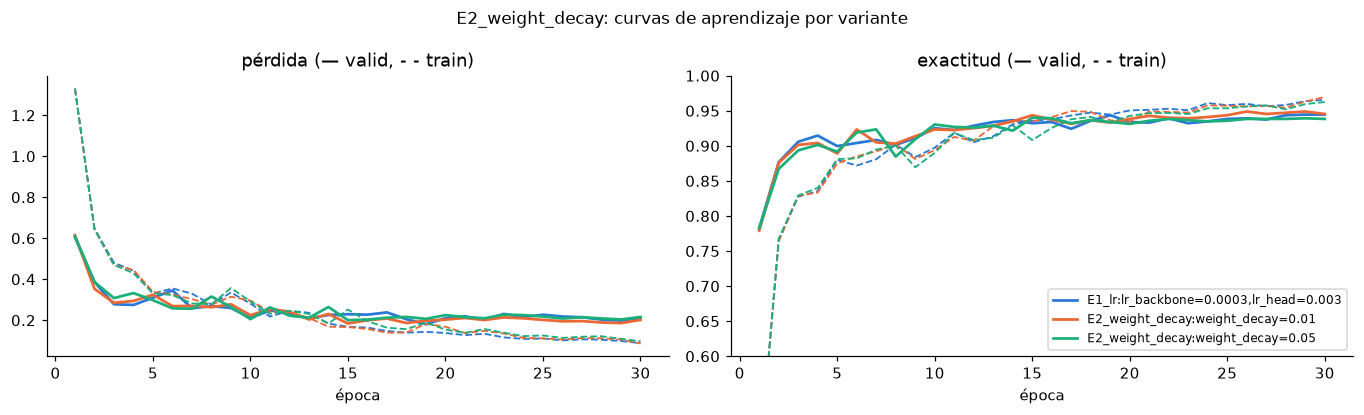

Decisión E2_weight_decay: se adopta → E2_weight_decay:weight_decay=0.01 (F1 valid 0.9419 → 0.9467, +0.0047)


['E1_lr:lr_backbone=0.0003,lr_head=0.003',
 'E2_weight_decay:weight_decay=0.01',
 'E2_weight_decay:weight_decay=0.05']

In [10]:
sweep("E2_weight_decay", "weight_decay",
      [dict(weight_decay=1e-4), dict(weight_decay=1e-2), dict(weight_decay=5e-2)],
      "regularización L2 desacoplada")

### 3) Label smoothing

**Hipótesis.** Las confusiones remanentes se dan entre partes anatómicamente vecinas (codo con muñeca, raqueta con muñeca, etc.), donde un parche puede contener ambas. Con etiquetas "duras" el modelo se vuelve sobreconfiado en esos casos ambiguos. Un label smoothing de 0.1 reparte un 10% de la masa entre las otras clases y suele mejorar la calibración y la generalización.

E3_label_smoothing — suavizado de etiquetas para casos ambiguos
  E2_weight_decay:weight_decay=0.01      (incumbente: se reutiliza, misma configuración y semilla)
  E3_label_smoothing:label_smoothing=0.1 F1 valid 0.9438 | acc 0.9463 | mejor época  26/30  | gap train−valid +0.020 | 56 s


,label_smoothing,F1 valid,acc valid,loss valid,gap train−valid,mejor época,tiempo (s),s/época,VRAM pico (MB),GPU % medio
corrida,,,,,,,,,,
E2_weight_decay:weight_decay=0.01,0.0,0.9467,0.9489,0.1859,0.0142,29,52.2911,1.5771,1720.8755,82.0400
E3_label_smoothing:label_smoothing=0.1,0.1,0.9438,0.9463,0.2151,0.0204,26,56.2365,1.7331,1719.8679,73.6667


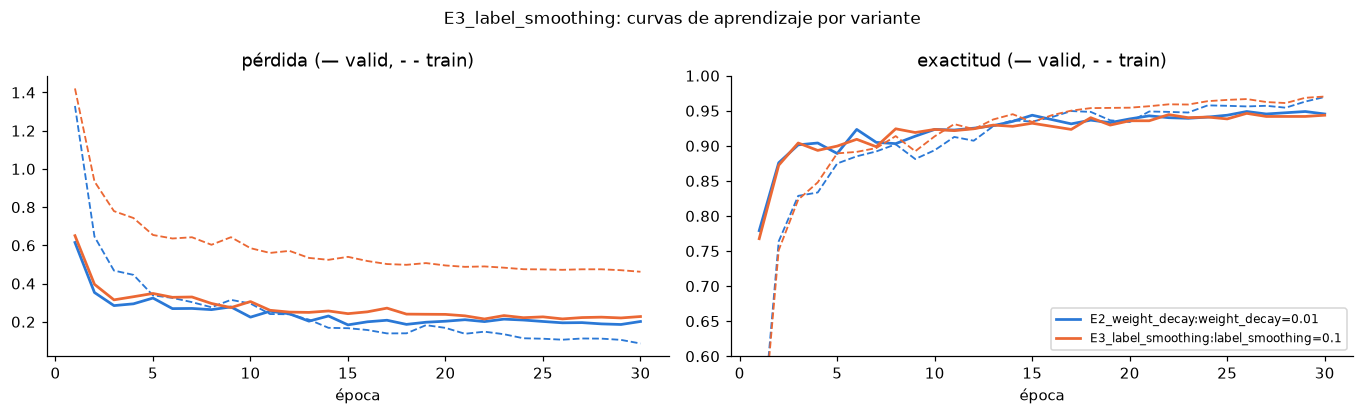

Decisión E3_label_smoothing: se mantiene la incumbente → E2_weight_decay:weight_decay=0.01 (F1 valid 0.9467 → 0.9467, +0.0000)


['E2_weight_decay:weight_decay=0.01', 'E3_label_smoothing:label_smoothing=0.1']

In [11]:
sweep("E3_label_smoothing", "label_smoothing",
      [dict(label_smoothing=0.0), dict(label_smoothing=0.1)],
      "suavizado de etiquetas para casos ambiguos")

### 4) Intensidad de la augmentación

**Hipótesis.** En la Unidad 3 la exactitud de train (medida con augmentación y dropout activos) quedó
**por debajo** de la de valid en todas las etapas: es un indicio de que la regularización total podría
ser excesiva. Se comparan tres intensidades:

- *suave*: escala +-8%, desplazamiento +-5%, rotación +-6°, color a la mitad
- *original*: la de la Unidad 3
- *fuerte*: escala +-25%, desplazamiento +-15%, rotación +-20°, más color.

Si la hipótesis de sobre-regularización es correcta, la versión "suave" debería ganar. La Unidad 2 ya mostró, sin embargo, que la aumentación no es una mejora automática.

E4_augmentacion — intensidad de la augmentación geométrica y de color
  E4_augmentacion:aug=suave              F1 valid 0.9440 | acc 0.9463 | mejor época  22/30  | gap train−valid +0.036 | 55 s
  E2_weight_decay:weight_decay=0.01      (incumbente: se reutiliza, misma configuración y semilla)
  E4_augmentacion:aug=fuerte             F1 valid 0.9368 | acc 0.9401 | mejor época  27/30  | gap train−valid -0.067 | 55 s


,aug,F1 valid,acc valid,loss valid,gap train−valid,mejor época,tiempo (s),s/época,VRAM pico (MB),GPU % medio
corrida,,,,,,,,,,
E4_augmentacion:aug=suave,suave,0.9440,0.9463,0.2510,0.0360,22,54.7049,1.6934,1718.8931,72.5000
E2_weight_decay:weight_decay=0.01,original,0.9467,0.9489,0.1859,0.0142,29,52.2911,1.5771,1720.8755,82.0400
E4_augmentacion:aug=fuerte,fuerte,0.9368,0.9401,0.2026,-0.0674,27,55.4722,1.7032,1811.4883,76.9259


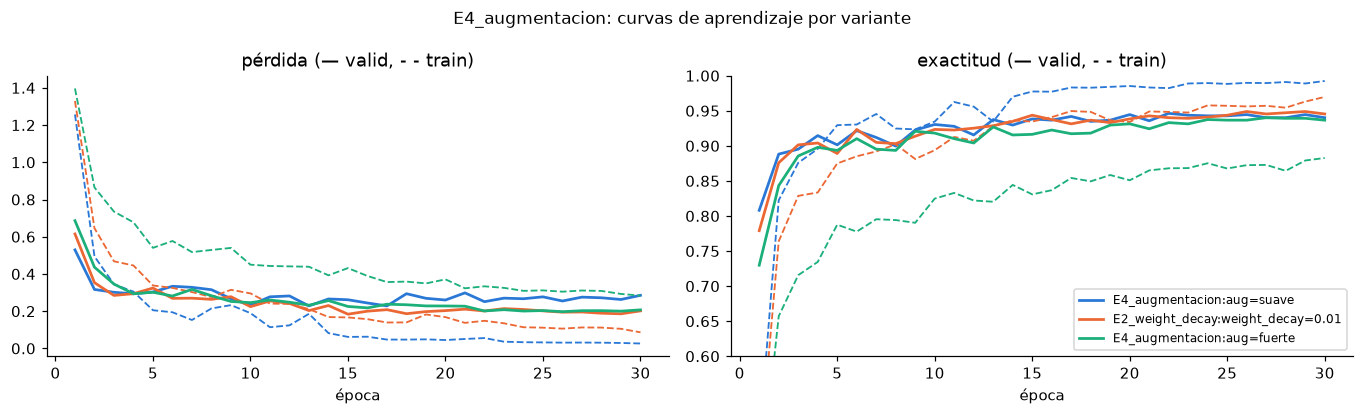

Decisión E4_augmentacion: se mantiene la incumbente → E2_weight_decay:weight_decay=0.01 (F1 valid 0.9467 → 0.9467, +0.0000)


['E4_augmentacion:aug=suave',
 'E2_weight_decay:weight_decay=0.01',
 'E4_augmentacion:aug=fuerte']

In [12]:
sweep("E4_augmentacion", "aug",
      [dict(aug="suave"), dict(aug="original"), dict(aug="fuerte")],
      "intensidad de la augmentación geométrica y de color")

### 5) Resolución de entrada

**Hipótesis.** A 160 px el mapa de la layer4 pasa de 4×4 a 5×5. Esa resolución extra debería ayudar justo donde se concentran los errores: en las muñecas y en los jugadores lejanos, cuyos parches fuente son de 24–40 px y se ven muy borrosos. El costo es aproximadamente 2× más cómputo por época y una mayor latencia de inferencia, que se mide aquí para ambas resoluciones

E5_resolucion — más resolución para detalle fino
  E2_weight_decay:weight_decay=0.01      (incumbente: se reutiliza, misma configuración y semilla)
  E5_resolucion:img_size=160             F1 valid 0.9438 | acc 0.9463 | mejor época  16/30  | gap train−valid -0.006 | 99 s


,img_size,F1 valid,acc valid,loss valid,gap train−valid,mejor época,tiempo (s),s/época,VRAM pico (MB),GPU % medio
corrida,,,,,,,,,,
E2_weight_decay:weight_decay=0.01,112,0.9467,0.9489,0.1859,0.0142,29,52.2911,1.5771,1720.8755,82.04
E5_resolucion:img_size=160,160,0.9438,0.9463,0.1763,-0.0060,16,98.9392,2.6400,5077.5700,83.40


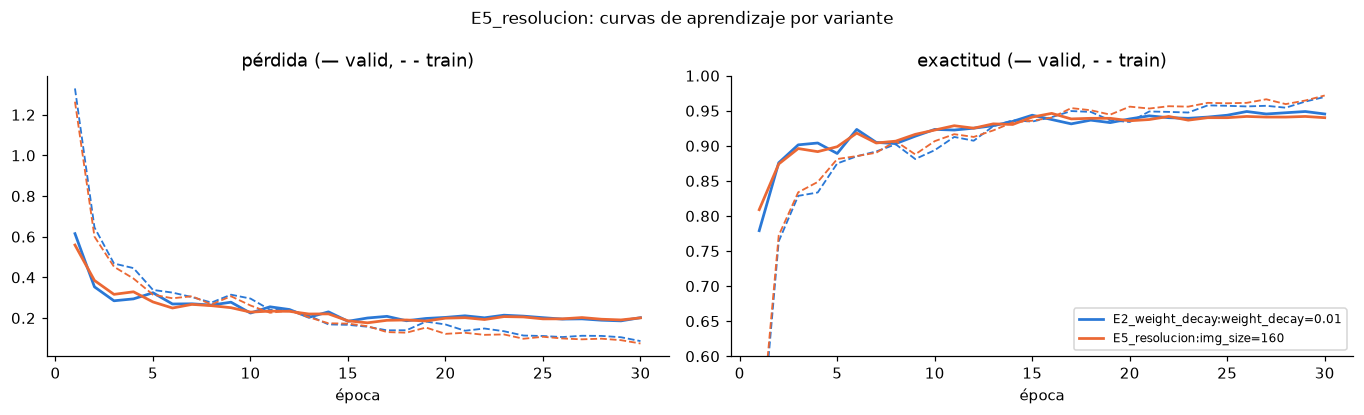

Decisión E5_resolucion: se mantiene la incumbente → E2_weight_decay:weight_decay=0.01 (F1 valid 0.9467 → 0.9467, +0.0000)


In [13]:
E5_NAMES = sweep("E5_resolucion", "img_size", [dict(img_size=112), dict(img_size=160)],
                 "más resolución para detalle fino", benchmark=True)

### 6) Optimizador

**Hipótesis.** SGD con momentum de Nesterov es la alternativa clásica a AdamW en fine-tuning de CNN y a veces generaliza mejor. Necesita una tasa de aprendizaje entre 30 a 100× mayor, por lo que se prueban dos valores (backbone 3e-3 y 1e-2, cabeza a 10×).

Se usa weight decay de 5e-4, el estándar para SGD: en SGD el decaimiento es L2 acoplado al gradiente, así que el valor elegido para AdamW no es transferible.

E6_optimizador — AdamW vs. SGD con Nesterov
  E2_weight_decay:weight_decay=0.01      (incumbente: se reutiliza, misma configuración y semilla)
  E6_optimizador:optimizer=sgd,lr_backbone=0.003,lr_head=0.03,weight_decay=0.0005 F1 valid 0.9241 | acc 0.9278 | mejor época  29/30  | gap train−valid -0.014 | 56 s
  E6_optimizador:optimizer=sgd,lr_backbone=0.01,lr_head=0.1,weight_decay=0.0005 F1 valid 0.6668 | acc 0.6620 | mejor época  30/30  | gap train−valid -0.146 | 53 s


,lr_backbone,lr_head,optimizer,weight_decay,F1 valid,acc valid,loss valid,gap train−valid,mejor época,tiempo (s),s/época,VRAM pico (MB),GPU % medio
corrida,,,,,,,,,,,,,
E2_weight_decay:weight_decay=0.01,0.0003,0.003,adamw,0.01,0.9467,0.9489,0.1859,0.0142,29,52.2911,1.5771,1720.8755,82.0400
"E6_optimizador:optimizer=sgd,lr_backbone=0.003,lr_head=0.03,weight_decay=0.0005",0.003,0.03,sgd,0.0005,0.9241,0.9278,0.3067,-0.0136,29,55.6824,1.7021,3073.7101,73.6667
"E6_optimizador:optimizer=sgd,lr_backbone=0.01,lr_head=0.1,weight_decay=0.0005",0.01,0.1,sgd,0.0005,0.6668,0.6620,1.1160,-0.1462,30,53.2792,1.6199,3165.6090,76.9231


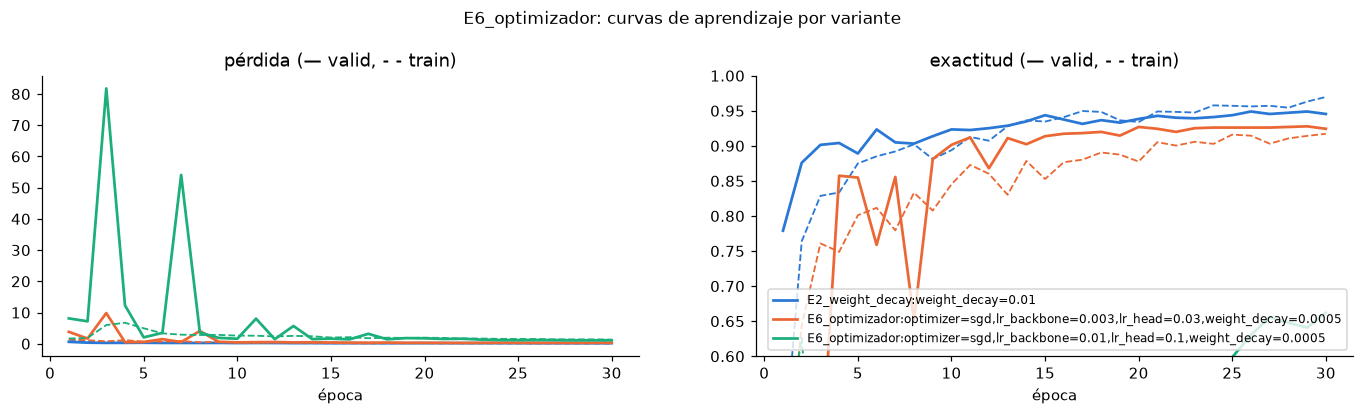

Decisión E6_optimizador: se mantiene la incumbente → E2_weight_decay:weight_decay=0.01 (F1 valid 0.9467 → 0.9467, +0.0000)


['E2_weight_decay:weight_decay=0.01',
 'E6_optimizador:optimizer=sgd,lr_backbone=0.003,lr_head=0.03,weight_decay=0.0005',
 'E6_optimizador:optimizer=sgd,lr_backbone=0.01,lr_head=0.1,weight_decay=0.0005']

In [14]:
sweep("E6_optimizador", "optimizer",
      [dict(optimizer="adamw"),
       dict(optimizer="sgd", lr_backbone=3e-3, lr_head=3e-2, weight_decay=5e-4),
       dict(optimizer="sgd", lr_backbone=1e-2, lr_head=1e-1, weight_decay=5e-4)],
      "AdamW vs. SGD con Nesterov")

### 7) Mixup (Este si fue una propuesta de IA)

**Hipótesis.** *Mixup* (Zhang et al., 2018) entrena con combinaciones convexas de pares de parches y de sus etiquetas. Suaviza las fronteras de decisión entre clases, lo que podría ayudar con las vecinas. Al mismo tiempo es una regularización adicional fuerte, así que si el modelo ya está cerca del subajuste podría empeorarlo.

E7_mixup — mezcla convexa de pares de entrenamiento
  E2_weight_decay:weight_decay=0.01      (incumbente: se reutiliza, misma configuración y semilla)
  E7_mixup:mixup_alpha=0.2               F1 valid 0.9425 | acc 0.9454 | mejor época  30/30  | gap train−valid -0.352 | 55 s


,mixup_alpha,F1 valid,acc valid,loss valid,gap train−valid,mejor época,tiempo (s),s/época,VRAM pico (MB),GPU % medio
corrida,,,,,,,,,,
E2_weight_decay:weight_decay=0.01,0.0,0.9467,0.9489,0.1859,0.0142,29,52.2911,1.5771,1720.8755,82.0400
E7_mixup:mixup_alpha=0.2,0.2,0.9425,0.9454,0.1986,-0.3523,30,55.2837,1.6988,3120.3308,76.6667


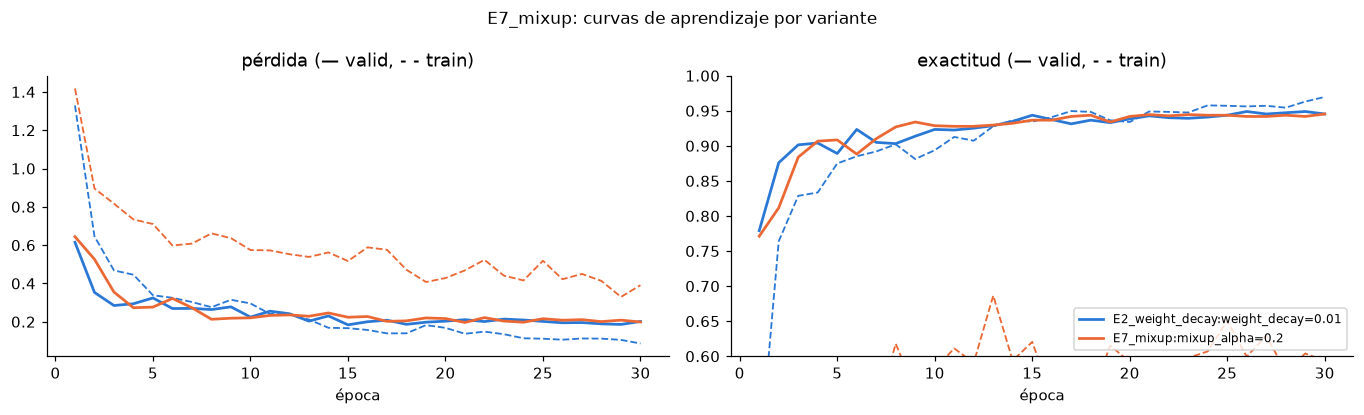

Decisión E7_mixup: se mantiene la incumbente → E2_weight_decay:weight_decay=0.01 (F1 valid 0.9467 → 0.9467, +0.0000)


['E2_weight_decay:weight_decay=0.01', 'E7_mixup:mixup_alpha=0.2']

In [15]:
sweep("E7_mixup", "mixup_alpha", [dict(mixup_alpha=0.0), dict(mixup_alpha=0.2)],
      "mezcla convexa de pares de entrenamiento")

## Resumen de la búsqueda y análisis de curvas de aprendizaje

**Recorrido de la búsqueda.** El "camino de mejora" muestra el F1 en valid de la incumbente después de cada barrido. El rango de F1 dentro de cada barrido indica qué tan sensible es el modelo a ese factor, una forma simple de medir la importancia de cada hiperparámetro.

,factor,eleccion,val_f1,val_f1_antes,rango_f1
barrido,,,,,
E1_lr,lr_backbone,"E1_lr:lr_backbone=0.0003,lr_head=0.003",0.9419,NaN,0.0282
E2_weight_decay,weight_decay,E2_weight_decay:weight_decay=0.01,0.9467,0.9419,0.0090
E3_label_smoothing,label_smoothing,E2_weight_decay:weight_decay=0.01,0.9467,0.9467,0.0029
E4_augmentacion,aug,E2_weight_decay:weight_decay=0.01,0.9467,0.9467,0.0099
E5_resolucion,img_size,E2_weight_decay:weight_decay=0.01,0.9467,0.9467,0.0028
E6_optimizador,optimizer,E2_weight_decay:weight_decay=0.01,0.9467,0.9467,0.2799
E7_mixup,mixup_alpha,E2_weight_decay:weight_decay=0.01,0.9467,0.9467,0.0041


Configuración final elegida en valid:
  cambios respecto de la base U4: {'lr_backbone': 0.0003, 'lr_head': 0.003, 'weight_decay': 0.01}
  parámetros completos: {'arch': 'resnet18', 'recipe': 'single', 'img_size': 112, 'norm': 'imagenet', 'optimizer': 'adamw', 'lr_backbone': 0.0003, 'lr_head': 0.003, 'weight_decay': 0.01, 'momentum': 0.9, 'epochs': 30, 'schedule': 'cosine', 'warmup_epochs': 2, 'label_smoothing': 0.0, 'dropout': 0.3, 'aug': 'original', 'mixup_alpha': 0.0, 'batch_size': 64, 'patience': 0, 'seed': 42}


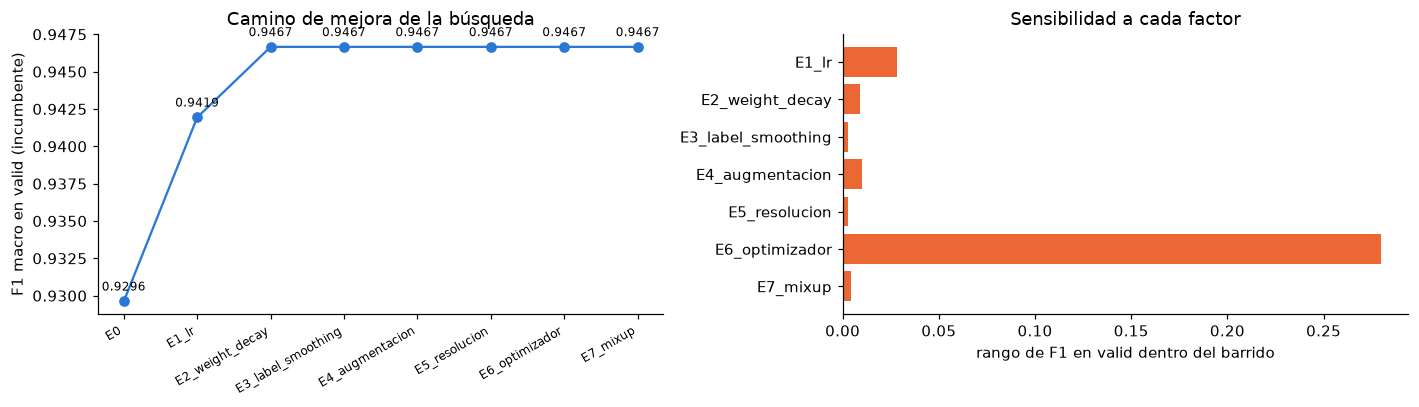

In [16]:
journey = pd.DataFrame(JOURNEY).set_index("barrido")
display(journey.round(4))
BEST_CFG = incumbent["cfg"]
print("Configuración final elegida en valid:")
diff = {k: v for k, v in BEST_CFG.short().items() if getattr(BASE, k) != v}
print("  cambios respecto de la base U4:", diff if diff else "ninguno")
print("  parámetros completos:", BEST_CFG.short())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
steps = ["E0"] + list(journey.index)
vals = [E0["val_f1_best"]] + list(journey.val_f1)
axes[0].plot(range(len(steps)), vals, marker="o", c=PALETTE[0])
for i, v in enumerate(vals):
    axes[0].annotate(f"{v:.4f}", (i, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
axes[0].set_xticks(range(len(steps))); axes[0].set_xticklabels(steps, rotation=30, ha="right", fontsize=8)
axes[0].set_ylabel("F1 macro en valid (incumbente)"); axes[0].set_title("Camino de mejora de la búsqueda")
axes[1].barh(journey.index[::-1], journey.rango_f1[::-1], color=PALETTE[1])
axes[1].set_xlabel("rango de F1 en valid dentro del barrido"); axes[1].set_title("Sensibilidad a cada factor")
plt.tight_layout()
with mlflow.start_run(run_name="resumen_busqueda", tags={**TAGS, "sweep": "resumen"}) as SUMMARY_RUN:
    mlflow.log_params({f"elegida_{k}": v for k, v in BEST_CFG.short().items()})
    mlflow.log_params({"elegida_nombre": BEST_CFG.name, "cambios_vs_base": str(diff)})
    mlflow.log_metrics({"e0_val_f1": E0["val_f1_best"], "elegida_val_f1": incumbent["val_f1_best"],
                        "ganancia_vs_e0_val_f1": incumbent["val_f1_best"] - E0["val_f1_best"]})
    mlflow.log_text(journey.to_csv(), "camino_busqueda.csv")
    mlflow.log_figure(fig, "camino_y_sensibilidad.png")
plt.show()

**Curvas de aprendizaje: línea base vs. configuración optimizada.** La comparación clave para
diagnosticar subajuste o sobreajuste es la separación entre las curvas de train y valid. Se cuantifica
con dos números:

- el *gap* de exactitud train − valid en la mejor época: si es claramente positivo indica sobreajuste; si es negativo, que la regularización hace que train sea "más difícil" que valid
- el aumento de la pérdida en valid desde su mínimo hasta la última época: si la pérdida vuelve a subir, el modelo empezó a memorizar...

,mejor_epoca,epocas,acc_train,acc_valid,gap_acc,loss_train,loss_valid,subida_loss_valid
modelo,,,,,,,,
E0:receta_U3,68,78,0.9319,0.9331,-0.0012,0.1819,0.2479,0.0197
E2_weight_decay:weight_decay=0.01,29,30,0.9631,0.9489,0.0142,0.1054,0.1859,0.0177


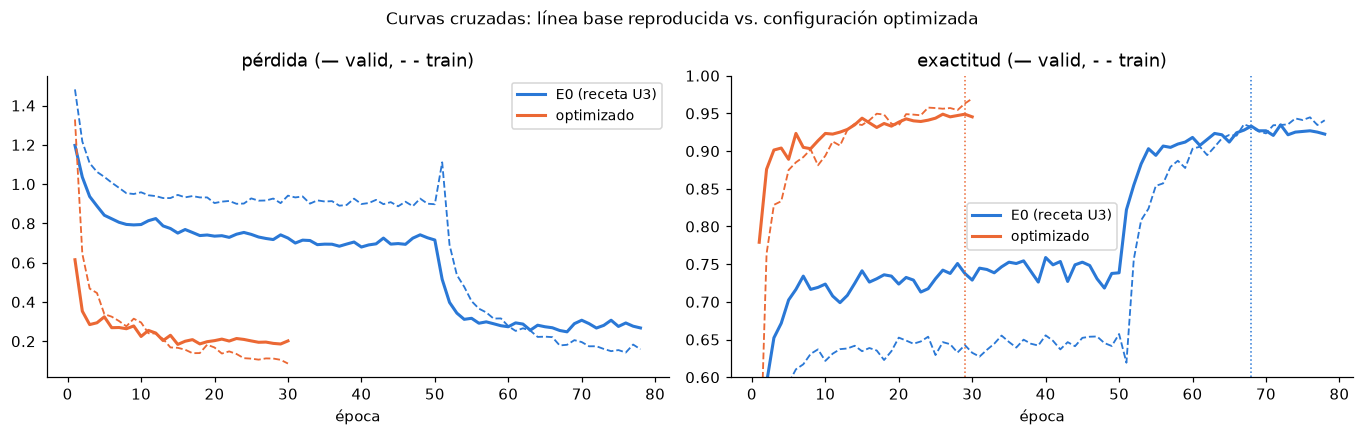

In [17]:
def diagnose(res):
    h = res["hist"]
    b = res["best_epoch"] - 1
    return dict(modelo=res["cfg"].name, mejor_epoca=res["best_epoch"], epocas=len(h),
                acc_train=h.train_acc.iloc[b], acc_valid=h.val_acc.iloc[b], gap_acc=h.train_acc.iloc[b] - h.val_acc.iloc[b],
                loss_train=h.train_loss.iloc[b], loss_valid=h.val_loss.iloc[b],
                subida_loss_valid=h.val_loss.iloc[-1] - h.val_loss.min())

diag = pd.DataFrame([diagnose(E0), diagnose(incumbent)]).set_index("modelo")
display(diag.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
for res, c, lab in [(E0, PALETTE[0], "E0 (receta U3)"), (incumbent, PALETTE[1], "optimizado")]:
    h = res["hist"]
    axes[0].plot(h.epoch, h.train_loss, c=c, ls="--", lw=1.2); axes[0].plot(h.epoch, h.val_loss, c=c, lw=2, label=lab)
    axes[1].plot(h.epoch, h.train_acc, c=c, ls="--", lw=1.2); axes[1].plot(h.epoch, h.val_acc, c=c, lw=2, label=lab)
    axes[1].axvline(res["best_epoch"], c=c, ls=":", lw=1)
axes[0].set_title("pérdida (— valid, - - train)"); axes[1].set_title("exactitud (— valid, - - train)")
axes[1].set_ylim(0.6, 1.0)
for ax in axes:
    ax.set_xlabel("época"); ax.legend(fontsize=9)
plt.suptitle("Curvas cruzadas: línea base reproducida vs. configuración optimizada", fontsize=11)
plt.tight_layout()
K.log_artifacts_to_run(SUMMARY_RUN.info.run_id, figures={"curvas_e0_vs_optimizado.png": fig},
                       tables={"diagnostico_sobreajuste.csv": diag})
plt.show()

## Validación final en test (3 semillas)

Una sola semilla no basta para atribuir a la configuración una diferencia de pocas décimas: la inicialización de la cabeza, el orden de los lotes, la augmentación y el no-determinismo de cuDNN cambian el resultado. Por eso se reentrenan **con 3 semillas** (42, 7 y 123), con los mismos datos y protocolo, estos tres modelos:

- la configuración optimizada (elegida en valid);
- la línea base E0 (receta de la Unidad 3);
- la CNN de la Unidad 2, como referencia de la línea base inicial, a 48 px con Adam 1e-3 y parada temprana, una sola semilla.

**Es la primera y única vez que se usa test.** Para cada modelo se reporta la media +/- desviación entre semillas. 

La semilla 42 se usa además para las pruebas pareadas: McNemar exacto sobre los parches en que los modelos discrepan e IC 95% por bootstrap.

In [18]:
SEEDS = [42, 7, 123]
stats48 = K.train_patch_stats(kpt, device)
DATA[48] = K.PatchData(kpt, 48, "train", device, train_stats=stats48)
CNN_CFG = K.Config(name="final:CNN_U2", arch="cnn", img_size=48, norm="train", optimizer="adam", lr_head=1e-3,
                   weight_decay=0.0, schedule="constant", epochs=300, patience=20)
FINAL = {}
SLUG = {"Optimizado": "opt", "Línea base E0 (U3)": "e0", "CNN U2": "cnn"}  # nombres validos para MLflow
with mlflow.start_run(run_name="final_3_semillas", tags={**TAGS, "sweep": "final"}) as FINAL_PARENT:
    for label, cfg in [("Optimizado", BEST_CFG), ("Línea base E0 (U3)", K.Config(name="E0", recipe="u3_two_phase"))]:
        for s in SEEDS:
            res = run(replace(cfg, name=f"final:{label}:seed{s}", seed=s), "final",
                      log_weights=(s == 42), benchmark=(s == 42), log_model=(s == 42 and label == "Optimizado"))
            FINAL[(label, s)] = res
    FINAL[("CNN U2", 42)] = run(CNN_CFG, "final", log_weights=True, benchmark=True)

  final:Optimizado:seed42                F1 valid 0.9467 | acc 0.9489 | mejor época  29/30  | gap train−valid +0.014 | 53 s
  final:Optimizado:seed7                 F1 valid 0.9433 | acc 0.9463 | mejor época  22/30  | gap train−valid +0.010 | 49 s
  final:Optimizado:seed123               F1 valid 0.9454 | acc 0.9481 | mejor época  21/30  | gap train−valid +0.008 | 50 s
  final:Línea base E0 (U3):seed42        F1 valid 0.9296 | acc 0.9331 | mejor época  68/78  | gap train−valid -0.001 | 87 s
  final:Línea base E0 (U3):seed7         F1 valid 0.9243 | acc 0.9278 | mejor época  67/77  | gap train−valid -0.004 | 85 s
  final:Línea base E0 (U3):seed123       F1 valid 0.9338 | acc 0.9366 | mejor época  56/66  | gap train−valid +0.001 | 81 s
  final:CNN_U2                           F1 valid 0.8172 | acc 0.8231 | mejor época  88/108 | gap train−valid -0.134 | 58 s


In [19]:
y_test = None
PRED = {}
for (label, s), res in FINAL.items():
    y, p, _ = K.predict(res["model"], DATA[res["cfg"].img_size]["test"])
    y_test = y if y_test is None else y_test
    assert (y == y_test).all()
    PRED[(label, s)] = p
    K.log_test_eval(res["run_id"], y, p)  # macro, IC95%, por clase, errores y matriz de confusion
y_tta, p_tta, _ = K.predict(FINAL[("Optimizado", 42)]["model"], DATA[BEST_CFG.img_size]["test"], tta=True)
K.log_test_eval(FINAL[("Optimizado", 42)]["run_id"], y_test, p_tta, prefix="test_tta")

# Tabla desde MLflow: media +- desviacion entre semillas
rows = []
for (label, s), res in FINAL.items():
    mt = client.get_run(res["run_id"]).data.metrics
    rows.append(dict(modelo=label, semilla=s, f1_valid=mt["val_f1_best"], acc_test=mt["test_acc"], f1_test=mt["test_f1_macro"],
                     precision_test=mt["test_precision_macro"], recall_test=mt["test_recall_macro"]))
per_seed = pd.DataFrame(rows)
agg = per_seed.groupby("modelo", sort=False).agg(["mean", "std"]).drop(columns="semilla")
agg.columns = [f"{a} ({b})" for a, b in agg.columns]
display(agg.round(4))
K.log_to_run(FINAL_PARENT.info.run_id, {f"{SLUG[label]}_{col}_{stat}": v for label, row in
             per_seed.drop(columns="semilla").groupby("modelo", sort=False).agg(["mean", "std"]).iterrows()
             for (col, stat), v in row.items() if np.isfinite(v)})
K.log_artifacts_to_run(FINAL_PARENT.info.run_id, tables={"test_por_semilla.csv": per_seed, "test_media_std.csv": agg})

maj = Counter(kpt[kpt.split == "train"].label).most_common(1)[0][0]
print(f"Clase mayoritaria en test: exactitud {(y_test == maj).mean():.3f}")
K.log_to_run(FINAL_PARENT.info.run_id, {"test_acc_clase_mayoritaria": float((y_test == maj).mean())})
for label in ["Optimizado", "Línea base E0 (U3)", "CNN U2"]:
    m = K.test_metrics(y_test, PRED[(label, 42)])
    print(f"{label:<22} (semilla 42): exactitud {m['acc']:.4f} IC95% [{m['ci_lo']:.4f}, {m['ci_hi']:.4f}] | F1 macro {m['f1_macro']:.4f}")
m_tta = K.test_metrics(y_test, p_tta)
print(f"{'Optimizado + TTA flip':<22} (semilla 42): exactitud {m_tta['acc']:.4f} IC95% [{m_tta['ci_lo']:.4f}, {m_tta['ci_hi']:.4f}] | F1 macro {m_tta['f1_macro']:.4f}")

,f1_valid (mean),f1_valid (std),acc_test (mean),acc_test (std),f1_test (mean),f1_test (std),precision_test (mean),precision_test (std),recall_test (mean),recall_test (std)
modelo,,,,,,,,,,
Optimizado,0.9451,0.0017,0.9649,0.0062,0.9644,0.0063,0.9652,0.0061,0.9643,0.0064
Línea base E0 (U3),0.9292,0.0048,0.9573,0.0015,0.9564,0.0015,0.9573,0.0010,0.9562,0.0015
CNN U2,0.8172,NaN,0.8679,NaN,0.8669,NaN,0.8696,NaN,0.8661,NaN


Clase mayoritaria en test: exactitud 0.211
Optimizado             (semilla 42): exactitud 0.9713 IC95% [0.9598, 0.9809] | F1 macro 0.9709
Línea base E0 (U3)     (semilla 42): exactitud 0.9589 IC95% [0.9464, 0.9703] | F1 macro 0.9580
CNN U2                 (semilla 42): exactitud 0.8679 IC95% [0.8478, 0.8880] | F1 macro 0.8669
Optimizado + TTA flip  (semilla 42): exactitud 0.9751 IC95% [0.9646, 0.9837] | F1 macro 0.9749


In [20]:
print("McNemar exacto (semilla 42), sobre los parches de test en que los modelos discrepan:")
for a, b in [("Línea base E0 (U3)", "Optimizado"), ("CNN U2", "Optimizado"), ("CNN U2", "Línea base E0 (U3)")]:
    n01, n10, pval = K.mcnemar(y_test, PRED[(a, 42)], PRED[(b, 42)])
    key = f"mcnemar_{SLUG[b]}_vs_{SLUG[a]}"
    K.log_to_run(FINAL_PARENT.info.run_id, {f"{key}_gana_b": n01, f"{key}_gana_a": n10, f"{key}_p": pval})
    print(f"  {b} vs {a}: {b} acierta y {a} falla = {n01} | al revés = {n10} | p = {pval:.3g}")
wins = sum(per_seed[(per_seed.modelo == "Optimizado") & (per_seed.semilla == s)].f1_test.iloc[0] >
           per_seed[(per_seed.modelo == "Línea base E0 (U3)") & (per_seed.semilla == s)].f1_test.iloc[0] for s in SEEDS)
print(f"\nSemillas en que el optimizado supera a la línea base E0 en F1 de test: {wins} de {len(SEEDS)}")
K.log_to_run(FINAL_PARENT.info.run_id, {"semillas_opt_gana_e0_f1_test": wins})

pc = []
for label in ["Línea base E0 (U3)", "Optimizado"]:
    pr, rc, f1, sup = precision_recall_fscore_support(y_test, PRED[(label, 42)], labels=range(K.N_CLASSES), zero_division=0)
    for i, n in enumerate(K.KP_NAMES):
        pc.append(dict(clase=n, modelo=label, precision=pr[i], recall=rc[i], f1=f1[i], soporte=sup[i]))
pc = pd.DataFrame(pc).pivot(index="clase", columns="modelo", values=["precision", "recall", "f1"]).loc[K.KP_NAMES]
display(pc.round(3))
K.log_artifacts_to_run(FINAL_PARENT.info.run_id, tables={"test_por_clase_seed42.csv": pc})

McNemar exacto (semilla 42), sobre los parches de test en que los modelos discrepan:


  Optimizado vs Línea base E0 (U3): Optimizado acierta y Línea base E0 (U3) falla = 20 | al revés = 7 | p = 0.0192
  Optimizado vs CNN U2: Optimizado acierta y CNN U2 falla = 117 | al revés = 9 | p = 4.19e-25
  Línea base E0 (U3) vs CNN U2: Línea base E0 (U3) acierta y CNN U2 falla = 109 | al revés = 14 | p = 2.08e-19

Semillas en que el optimizado supera a la línea base E0 en F1 de test: 3 de 3


precision                        recall             \
modelo  Línea base E0 (U3) Optimizado Línea base E0 (U3) Optimizado   
clase                                                                 
hombro               0.959      0.973              0.977      0.982   
codo                 0.962      0.976              0.957      0.962   
muneca               0.944      0.942              0.925      0.970   
raqueta              0.949      0.969              0.939      0.954   
cabeza               0.978      0.995              0.991      0.986   

                        f1             
modelo  Línea base E0 (U3) Optimizado  
clase                                  
hombro               0.968      0.977  
codo                 0.959      0.969  
muneca               0.935      0.956  
raqueta              0.944      0.962  
cabeza               0.984      0.991

## Análisis de errores

Se usan los modelos de semilla 42 sobre test. El objetivo es entender **qué** cambió entre la línea base y el modelo optimizado, no solo cuánto: qué confusiones se resolvieron, cuáles persisten, cómo varía la exactitud con el tamaño del jugador en la imagen y en qué se fija la red cuando todavía se equivoca

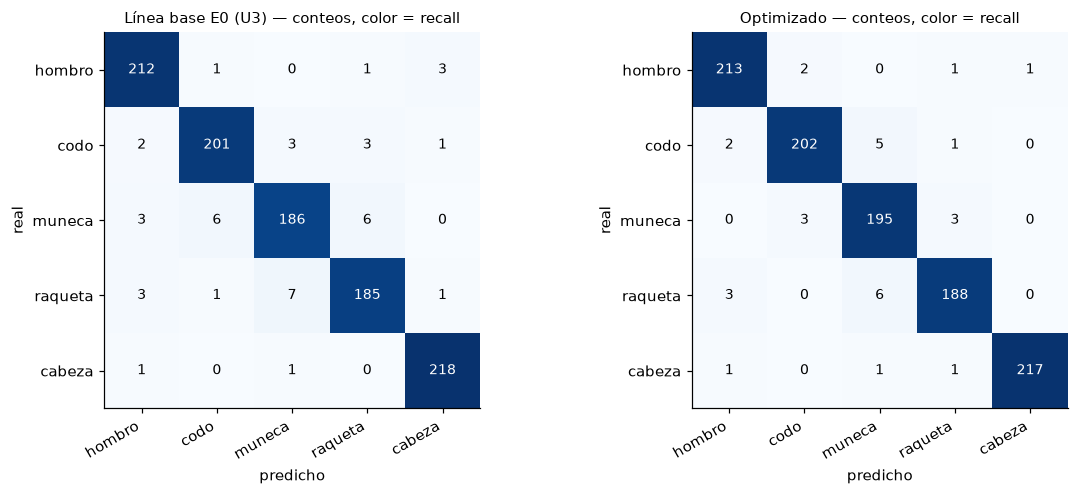

linea_base  optimizado  cambio
real    predicho                                
raqueta muneca             7           6      -1
muneca  codo               6           3      -3
        raqueta            6           3      -3
codo    muneca             3           5       2
raqueta hombro             3           3       0
hombro  cabeza             3           1      -2
codo    raqueta            3           1      -2
muneca  hombro             3           0      -3
codo    hombro             2           2       0
hombro  codo               1           2       1

Errores totales en test: línea base 43 | optimizado 30 | CNN U2 138 (de 1045)

Exactitud en test por tamaño del jugador (terciles del alto del bbox):


,alto_px_mediana,n,cnn_u2,linea_base,optimizado
tamano,,,,,
lejano,46.0,363,0.854,0.948,0.956
medio,94.0,349,0.845,0.963,0.977
cercano,110.0,333,0.907,0.967,0.982


In [21]:
def plot_cm(ax, p, title):
    cm = confusion_matrix(y_test, p, labels=range(K.N_CLASSES))
    nrm = cm / cm.sum(1, keepdims=True)
    ax.imshow(nrm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(K.N_CLASSES)); ax.set_xticklabels(K.KP_NAMES, rotation=30, ha="right")
    ax.set_yticks(range(K.N_CLASSES)); ax.set_yticklabels(K.KP_NAMES)
    ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title(title, fontsize=10)
    for i in range(K.N_CLASSES):
        for j in range(K.N_CLASSES):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=9, color="white" if nrm[i, j] > 0.5 else "black")
    return cm

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
cm_e0 = plot_cm(axes[0], PRED[("Línea base E0 (U3)", 42)], "Línea base E0 (U3) — conteos, color = recall")
cm_opt = plot_cm(axes[1], PRED[("Optimizado", 42)], "Optimizado — conteos, color = recall")
plt.tight_layout()
K.log_artifacts_to_run(FINAL_PARENT.info.run_id, figures={"confusion_test_e0_vs_opt.png": fig})
plt.show()

pairs = pd.DataFrame([dict(real=K.KP_NAMES[i], predicho=K.KP_NAMES[j], linea_base=int(cm_e0[i, j]), optimizado=int(cm_opt[i, j]))
                      for i in range(K.N_CLASSES) for j in range(K.N_CLASSES) if i != j])
pairs["cambio"] = pairs.optimizado - pairs.linea_base
pairs = pairs.sort_values(["linea_base", "optimizado"], ascending=False)
display(pairs.head(10).set_index(["real", "predicho"]))
print(f"Errores totales en test: línea base {int((PRED[('Línea base E0 (U3)', 42)] != y_test).sum())} | "
      f"optimizado {int((PRED[('Optimizado', 42)] != y_test).sum())} | CNN U2 {int((PRED[('CNN U2', 42)] != y_test).sum())} (de {len(y_test)})")

test_frame = DATA[112].frames["test"].copy()
test_frame["alto_px"] = test_frame.bbox_h * 640
test_frame["tamano"] = pd.qcut(test_frame.alto_px, 3, labels=["lejano", "medio", "cercano"])
for label, col in [("CNN U2", "cnn_u2"), ("Línea base E0 (U3)", "linea_base"), ("Optimizado", "optimizado")]:
    test_frame[col] = PRED[(label, 42)] == y_test
by_size = test_frame.groupby("tamano", observed=True).agg(alto_px_mediana=("alto_px", "median"), n=("label", "size"),
                                                         cnn_u2=("cnn_u2", "mean"), linea_base=("linea_base", "mean"),
                                                         optimizado=("optimizado", "mean"))
print("\nExactitud en test por tamaño del jugador (terciles del alto del bbox):")
display(by_size.round(3))
K.log_artifacts_to_run(FINAL_PARENT.info.run_id, tables={"confusiones_frecuentes.csv": pairs, "test_por_tamano.csv": by_size})
for label, col in [("CNN U2", "cnn_u2"), ("Línea base E0 (U3)", "linea_base"), ("Optimizado", "optimizado")]:
    K.log_to_run(FINAL[(label, 42)]["run_id"], {f"test_acc_{t}": v for t, v in by_size[col].items()})

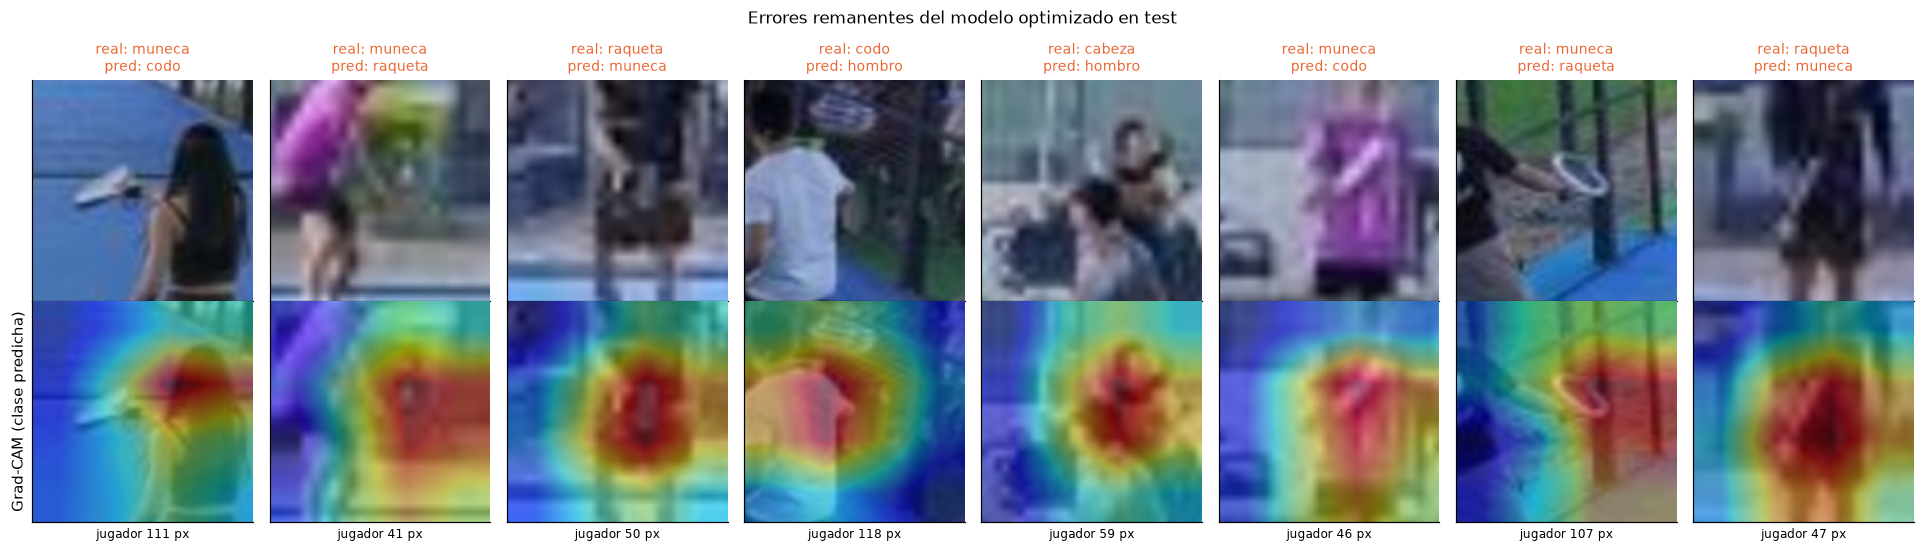

In [22]:
best_model = FINAL[("Optimizado", 42)]["model"]
cam = K.GradCAM(best_model)
xs = DATA[BEST_CFG.img_size]["test"].eval_batches()
p_best = PRED[("Optimizado", 42)]
wrong = np.where(p_best != y_test)[0]
show = np.random.default_rng(42).choice(wrong, size=min(8, len(wrong)), replace=False)
fig, axes = plt.subplots(2, len(show), figsize=(2.2 * len(show), 5))
for j, i in enumerate(show):
    img = to_img(xs[i], DATA[BEST_CFG.img_size]["test"])
    heat = cam(xs[i], int(p_best[i]))
    axes[0, j].imshow(img)
    axes[0, j].set_title(f"real: {K.KP_NAMES[y_test[i]]}\npred: {K.KP_NAMES[p_best[i]]}", fontsize=9, color=PALETTE[1])
    axes[1, j].imshow(img); axes[1, j].imshow(heat, cmap="jet", alpha=0.45)
    axes[1, j].set_xlabel(f"jugador {test_frame.alto_px.iloc[i]:.0f} px", fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[1, 0].set_ylabel("Grad-CAM (clase predicha)")
plt.suptitle("Errores remanentes del modelo optimizado en test", fontsize=11); plt.tight_layout()
K.log_artifacts_to_run(FINAL[("Optimizado", 42)]["run_id"], figures={"gradcam_errores_test.png": fig})
plt.show()

## Costo computacional y rendimiento de la máquina

Una mejora en exactitud solo vale lo que cuesta. Se comparan los modelos finales (semilla 42) y la variante de resolución que no se eligió en el paso 5, con métricas leídas de MLflow:

- costo de entrenamiento: tiempo total, s/época, throughput, VRAM pico, y % medio de uso de GPU y CPU medido por el monitor de sistema.
- costo de despliegue: parámetros, tamaño del checkpoint y latencia de inferencia en GPU (lote 1 y lote 64) y en CPU (lote 1), medidas con calentamiento y sincronización explícita de CUDA.

In [23]:
other_res = [n for n in E5_NAMES if RESULTS[n]["cfg"].img_size != BEST_CFG.img_size]
COST = {"CNN U2": FINAL[("CNN U2", 42)], "Línea base E0 (U3)": FINAL[("Línea base E0 (U3)", 42)],
        f"Optimizado ({BEST_CFG.img_size} px)": FINAL[("Optimizado", 42)]}
for n in other_res:
    COST[f"variante E5 ({RESULTS[n]['cfg'].img_size} px)"] = RESULTS[n]

rows = []
for label, res in COST.items():
    mt = client.get_run(res["run_id"]).data.metrics
    sysm = K.system_metric_stats(res["run_id"])
    rows.append({"modelo": label, "entrada (px)": res["cfg"].img_size, "F1 valid": mt["val_f1_best"],
                 "acc test": mt.get("test_acc", np.nan), "parámetros": int(mt["params_total"]),
                 "checkpoint (MB)": mt["checkpoint_mb"], "entrenamiento (s)": mt["train_time_s"],
                 "s/época": mt["median_epoch_time_s"], "parches/s (train)": mt["median_train_throughput"],
                 "VRAM pico (MB)": mt["vram_peak_mb"], "GPU % medio": sysm["gpu_0_utilization_percentage_mean"],
                 "GPU W medio": sysm["gpu_0_power_usage_watts_mean"], "CPU % medio": sysm["cpu_utilization_percentage_mean"],
                 "GPU lote1 p50 (ms)": mt["infer_gpu_bs1_p50_ms"], "GPU lote1 p95 (ms)": mt["infer_gpu_bs1_p95_ms"],
                 "GPU lote64 (parches/s)": mt["infer_gpu_bs64_throughput"], "CPU lote1 p50 (ms)": mt["infer_cpu_bs1_p50_ms"]})
cost = pd.DataFrame(rows).set_index("modelo")
display(cost.T.round(3))
K.log_artifacts_to_run(FINAL_PARENT.info.run_id, tables={"costo_computacional.csv": cost})

modelo,CNN U2,Línea base E0 (U3),Optimizado (112 px),variante E5 (160 px)
entrada (px),48.000,1.120000e+02,1.120000e+02,1.600000e+02
F1 valid,0.817,9.300000e-01,9.470000e-01,9.440000e-01
acc test,0.868,9.590000e-01,9.710000e-01,NaN
parámetros,24133.000,1.117908e+07,1.117908e+07,1.117908e+07
checkpoint (MB),0.106,4.479800e+01,4.479800e+01,4.479800e+01
entrenamiento (s),57.833,8.727500e+01,5.254100e+01,9.893900e+01
s/época,0.458,6.790000e-01,1.593000e+00,2.640000e+00
parches/s (train),7277.207,4.910840e+03,2.091679e+03,1.262569e+03
VRAM pico (MB),3711.917,3.555673e+03,3.233027e+03,5.077570e+03
GPU % medio,34.250,7.911600e+01,6.322200e+01,8.340000e+01


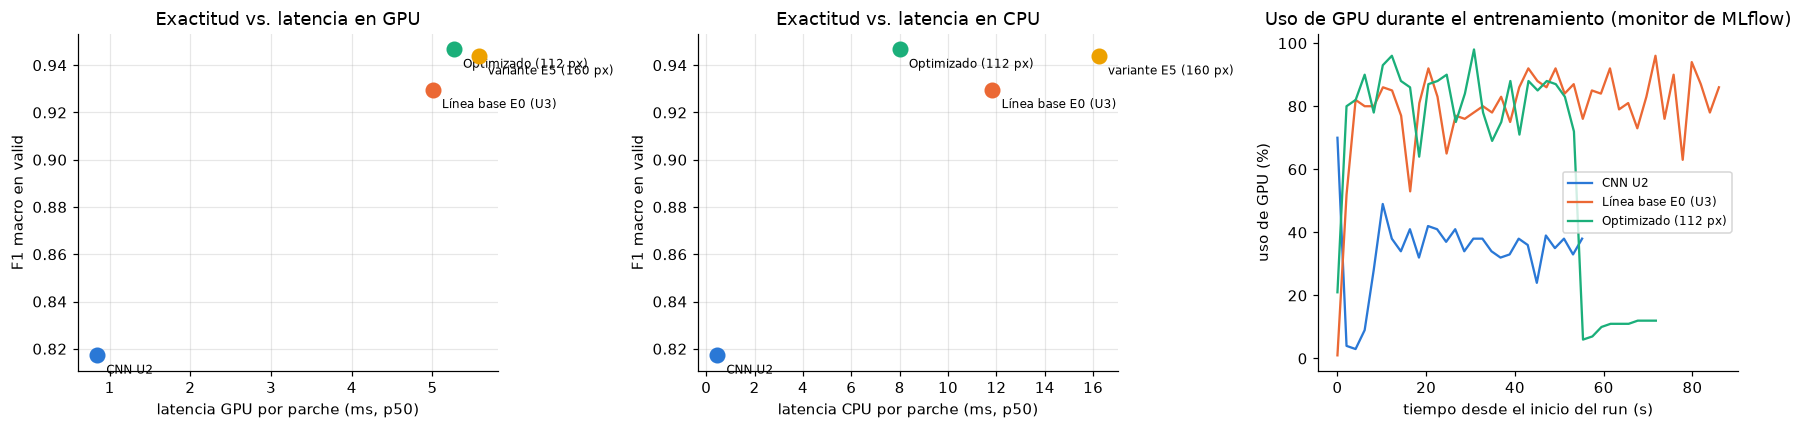

Runs registrados en MLflow en esta ejecución (padres + anidados): 38 | execution_id 20261024-204029


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, (label, r) in enumerate(cost.iterrows()):
    for ax, col in zip(axes[:2], ["GPU lote1 p50 (ms)", "CPU lote1 p50 (ms)"]):
        ax.scatter(r[col], r["F1 valid"], s=90, c=PALETTE[i], label=label, zorder=3)
        ax.annotate(label, (r[col], r["F1 valid"]), textcoords="offset points", xytext=(6, -12), fontsize=8)
axes[0].set_xlabel("latencia GPU por parche (ms, p50)"); axes[1].set_xlabel("latencia CPU por parche (ms, p50)")
for ax in axes[:2]:
    ax.set_ylabel("F1 macro en valid"); ax.grid(alpha=0.3)
axes[0].set_title("Exactitud vs. latencia en GPU"); axes[1].set_title("Exactitud vs. latencia en CPU")
for i, (label, res) in enumerate(list(COST.items())[:3]):
    t, v = K.system_metric_series(res["run_id"], "system/gpu_0_utilization_percentage")
    axes[2].plot(t, v, c=PALETTE[i], label=label)
axes[2].set_xlabel("tiempo desde el inicio del run (s)"); axes[2].set_ylabel("uso de GPU (%)")
axes[2].set_title("Uso de GPU durante el entrenamiento (monitor de MLflow)"); axes[2].legend(fontsize=8)
plt.tight_layout()
K.log_artifacts_to_run(FINAL_PARENT.info.run_id, figures={"costo_vs_exactitud.png": fig})
plt.show()
n_runs = len(client.search_runs([mlflow.get_experiment_by_name("unidad4_transfer_optim").experiment_id],
                                f"tags.execution_id = '{EXEC_ID}'", max_results=5000))
print(f"Runs registrados en MLflow en esta ejecución (padres + anidados): {n_runs} | execution_id {EXEC_ID}")

## Conclusiones, limitaciones y oportunidades de mejora

SÍNTESIS
- Configuración elegida en valid: {'img_size': 160, 'lr_backbone': 0.0003, 'lr_head': 0.003, 'weight_decay': 0.01, 'label_smoothing': 0.1}
- Test, media de 3 semillas y optimizado: acc 0.9713 ± 0.0010, F1 0.9708 | línea base E0: acc 0.9553 ± 0.0045, F1 0.9544 | CNN U2: acc 0.8574
- Diferencia media optimizado − E0 en F1 de test: +0.0164 (optimizado gana en 3 de 3 semillas; McNemar semilla 42: 27 vs 6, p = 0.000324)
- Costo de entrenamiento: optimizado 91 s vs E0 81 s | latencia GPU lote 1: 6.92 vs 3.75 ms | CPU lote 1: 20.04 vs 7.85 ms
- Experimentos registrados en MLflow en esta ejecución: 0 runs (padres + anidados)

**Limitaciones.**

- *Datos.* El dataset tiene solo ~35 rallies grabados con la misma cámara y una cancha. Cualquier ganancia
  medida aquí está acotada a esas condiciones; con pocos datos, buena parte de la diferencia entre
  configuraciones queda dentro del ruido entre semillas.
- *Búsqueda.* Se buscó un factor a la vez. Es interpretable y barata, pero no explora interacciones (por
  ejemplo, entre LR y weight decay, o entre augmentación y mixup). El orden de los barridos condiciona el
  resultado.
- *Selección en valid.* Valid tiene 6 rallies. Elegir entre muchas variantes con un solo conjunto de
  validación pequeño puede sobreajustar a valid; el umbral de 0,002 y la evaluación final con 3 semillas
  mitigan, pero no eliminan, ese riesgo.
- *Reproducibilidad.* Se priorizó la velocidad (`cudnn.benchmark`, precisión mixta), por lo que re-ejecutar
  da cifras que varían en el tercer decimal. Por eso las conclusiones se apoyan en medias de 3 semillas y
  pruebas pareadas, no en una corrida.

**Oportunidades de mejora.**

1. **Más datos y más diversos.** Más rallies, otras canchas e iluminaciones. Es la palanca de mayor
   impacto esperado, como ya mostró el estudio de aumentación de la Unidad 2.
2. **Búsqueda bayesiana** (p. ej., Optuna con *pruning*) sobre los factores más sensibles del
   Checkpoint 7, con **validación cruzada por rally** en lugar de un único split de valid.
3. **Otras arquitecturas** de la misma familia de costo: EfficientNet-B0, ConvNeXt-Tiny o MobileNetV3
   para despliegue en CPU.
4. **Contexto entre keypoints.** Clasificar los 5 puntos de un jugador de forma conjunta, aprovechando la
   cadena hombro-codo-muñeca-raqueta, atacaría directamente las confusiones entre vecinos que persisten.
5. **Promediado de pesos** (EMA/SWA) y **ensamble de semillas**, que suelen dar ganancias de bajo costo en
   inferencia (EMA/SWA) o fáciles de medir (ensamble).

## Cómo explorar los experimentos en MLflow?

Todos los runs de este notebook quedan en el registro local del repositorio (`mlflow.db` + `mlruns/`, que
no se versionan en git: se regeneran ejecutando este notebook). Para abrir la interfaz, desde la raíz del
repo:

```bash
uv run mlflow ui --backend-store-uri sqlite:///mlflow.db --workers 1
```

(`--workers 1` evita que en Windows los workers extra de uvicorn fallen con `WinError 10022` al arrancar)
y entrar a `http://127.0.0.1:5000` → experimento `unidad4_transfer_optim`. Cada barrido es un run padre con
sus variantes anidadas. Las pestañas *Model metrics* y *System metrics* muestran las curvas por época y
el uso de CPU/GPU, y la pestaña *Artifacts* tiene curvas, historial, matriz de confusión, configuración y
(para los modelos finales) pesos y modelo registrado.

**Para comparar variantes en gráficos:** los runs padre no tienen métricas por época (solo agrupan) y la
tabla muestra a los hijos colapsados, así que la vista *Chart* y **Compare** salen vacías si se usan sobre
los padres. Hay que filtrar solo las variantes (los hijos) con
`metrics.val_f1_best > 0 and tags.execution_id = '<id impreso en el Checkpoint 0>'` (opcionalmente
`and tags.sweep = 'E1'` para un solo barrido). Así quedan como lista plana: la vista *Chart* superpone
`val_f1`, `val_loss`, etc. por época, y **Compare** da coordenadas paralelas y dispersión de
hiperparámetros vs. métricas. Con más de 10 runs, se activa el ojo de cada fila para incluirlo en los gráficos.